In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.metrics import (
    make_scorer, accuracy_score, precision_score, 
    recall_score, f1_score, classification_report, 
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.base import clone, BaseEstimator, ClassifierMixin

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from scipy.stats import randint, uniform, loguniform

import time
import warnings
warnings.filterwarnings("ignore")

In [2]:
# TODO: Track train, test, and tuning time

# Set seed for reproducibility
seed = 67

# Show all dataframe columns
pd.set_option("display.max_columns", None)

# Seaborn plot colors
sns.set_palette("viridis")

# Phase columns
phase_cols     = ['BCC', 'FCC', 'IM', 'AM']
phase_combs    = ['BCC', 'FCC', 'BCC+FCC', 'AM', 'IM', 
                  'FCC+IM', 'FCC+AM', 'BCC+IM', 'BCC+AM', 
                  'BCC+FCC+IM', 'BCC+FCC+AM']
has_phase_cols = ['has_BCC', 'has_FCC', 'has_IM', 'has_AM']

# Setup

In [3]:
X_train      = pd.read_csv("data/X_train.csv", index_col=0)
X_test       = pd.read_csv("data/X_test.csv", index_col=0)
y_base_train = pd.read_csv("data/y_base_train.csv", index_col=0)
y_base_test  = pd.read_csv("data/y_base_test.csv", index_col=0)

In [4]:
# Save results
results = []

# Double points of minority classes, keep majority untouched
# Preserves relative gaps and increases minority representation
minority_double_strategy = {
    'IM': 898,
    'FCC+IM': 278,
    'FCC+AM': 230,
    'BCC+IM': 180,
    'BCC+AM': 114,
    'BCC+FCC+IM': 62,
    'BCC+FCC+AM': 50,
}

smote = SMOTE(sampling_strategy=minority_double_strategy, random_state=seed)

# Create scale -> SMOTE -> train pipeline
def create_pipe(clf):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('smote', smote),
        ('clf', clf),
    ])

In [5]:
# Setup metric lookups

_METRIC_DEFS = {
    "accuracy":           (accuracy_score,  {}),
    "precision_macro":    (precision_score, {"average": "macro",    "zero_division": 0}),
    "recall_macro":       (recall_score,    {"average": "macro",    "zero_division": 0}),
    "f1_macro":           (f1_score,        {"average": "macro",    "zero_division": 0}),
    "precision_weighted": (precision_score, {"average": "weighted", "zero_division": 0}),
    "recall_weighted":    (recall_score,    {"average": "weighted", "zero_division": 0}),
    "f1_weighted":        (f1_score,        {"average": "weighted", "zero_division": 0}),
}

SCORING = {name: make_scorer(f, **kw) for name, (f, kw) in _METRIC_DEFS.items()}

def _metrics(y_true, y_pred):
    return {name: f(y_true, y_pred, **kw) for name, (f, kw) in _METRIC_DEFS.items()}

In [6]:
def evaluate_model(model, X_train, y_train, X_test, y_test, name="model"):
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    tr = _metrics(y_train, y_train_pred)
    te = _metrics(y_test, y_test_pred)

    print(name)
    print(f"{'Metrics':<18} | {'Train':<6} | {'Test'}")
    print("-" * 40)
    for m in tr:
        print(f"{m:<18} | {tr[m]:<6.4f} | {te[m]:.4f}")
    print("")

    print(classification_report(y_test, y_test_pred, digits=4, zero_division=0))

    cm = confusion_matrix(y_test, y_test_pred, labels=phase_combs)
    fig, ax = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay(cm, display_labels=phase_combs).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Confusion matrix - {name}")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

    return {
        "name": name, "train": tr, "test": te, "cm": cm,
        "y_train_pred": y_train_pred, "y_test_pred": y_test_pred,
    }

In [7]:
def tune_model(pipe, param_distributions, X, y, *,
               n_iter=100, val_size=0.2, random_state=seed,
               scoring=SCORING["f1_macro"], name="model", n_jobs=-1, verbose=1):

    idx = np.arange(len(y))
    tr_idx, val_idx = train_test_split(idx, test_size=val_size, stratify=y, random_state=random_state)
    cv_single_split = [(tr_idx, val_idx)]

    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_distributions,
        n_iter=n_iter,
        scoring=scoring,
        cv=cv_single_split,
        refit=True,
        random_state=random_state,
        n_jobs=n_jobs,
        verbose=verbose,
    )
    search.fit(X, y)

    print(f"\n=== RandomizedSearchCV ({name}) ===")
    print(f"Best score: {search.best_score_:.4f}")
    for k, v in search.best_params_.items():
        print(f"  {k}: {v}")
    print("")

    return search

In [8]:
def run_model(name, estimator, param_dist, X_train, y_train, X_test, y_test, results, n_iter=100):
    default_pipe = create_pipe(clone(estimator))
    default_pipe.fit(X_train, y_train)
    results.append(evaluate_model(default_pipe, X_train, y_train, X_test, y_test, name=f"{name}_def"))

    search = tune_model(create_pipe(clone(estimator)), param_dist, X_train, y_train, name=name, n_iter=n_iter)
    tuned = search.best_estimator_
    results.append(evaluate_model(tuned, X_train, y_train, X_test, y_test, name=f"{name}_tun"))

    return results

In [9]:
def summarize_models(results):
    rows = []
    metric_order = list(_METRIC_DEFS.keys())
    for r in results:
        row = {"Model": r["name"]}
        for m in metric_order:
            row[m] = r["test"][m]
        rows.append(row)

    return pd.DataFrame(rows).set_index("Model")[metric_order]

# k-Nearest Neighbors

kNN_base_def
Metrics            | Train  | Test
----------------------------------------
accuracy           | 0.8875 | 0.8366
precision_macro    | 0.7493 | 0.6872
recall_macro       | 0.8324 | 0.7157
f1_macro           | 0.7783 | 0.6869
precision_weighted | 0.9028 | 0.8542
recall_weighted    | 0.8875 | 0.8366
f1_weighted        | 0.8913 | 0.8418

              precision    recall  f1-score   support

          AM     0.8689    0.7361    0.7970        72
         BCC     0.8859    0.8462    0.8656       156
      BCC+AM     0.5000    0.5000    0.5000         6
     BCC+FCC     0.8571    0.9057    0.8807       106
  BCC+FCC+AM     0.6667    1.0000    0.8000         2
  BCC+FCC+IM     0.2000    0.3333    0.2500         3
      BCC+IM     1.0000    0.5556    0.7143         9
         FCC     0.9695    0.9203    0.9442       138
      FCC+AM     0.3500    0.5833    0.4375        12
      FCC+IM     0.6250    0.7143    0.6667        14
          IM     0.6364    0.7778    0.7000        45

 

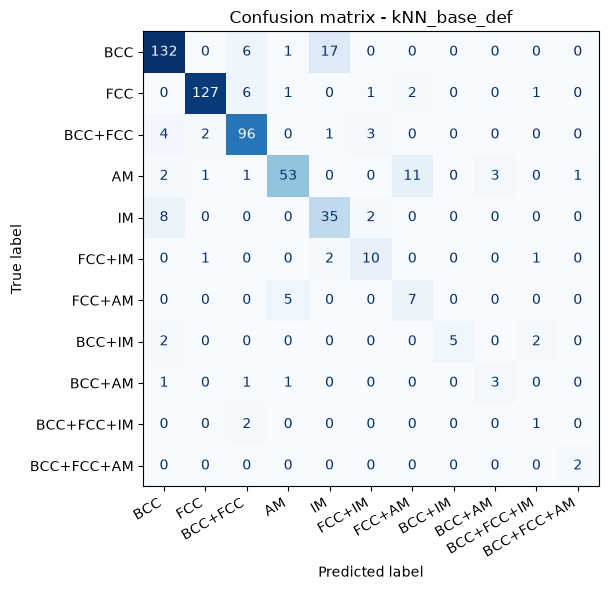

Fitting 1 folds for each of 100 candidates, totalling 100 fits

=== RandomizedSearchCV (kNN_base) ===
Best score: 0.6476
  clf__metric: euclidean
  clf__n_neighbors: 11
  clf__p: 2
  clf__weights: uniform

kNN_base_tun
Metrics            | Train  | Test
----------------------------------------
accuracy           | 0.8575 | 0.8259
precision_macro    | 0.6929 | 0.6789
recall_macro       | 0.7947 | 0.7436
f1_macro           | 0.7286 | 0.7005
precision_weighted | 0.8760 | 0.8423
recall_weighted    | 0.8575 | 0.8259
f1_weighted        | 0.8624 | 0.8305

              precision    recall  f1-score   support

          AM     0.9123    0.7222    0.8062        72
         BCC     0.8609    0.8333    0.8469       156
      BCC+AM     0.5000    0.6667    0.5714         6
     BCC+FCC     0.8273    0.8585    0.8426       106
  BCC+FCC+AM     0.6667    1.0000    0.8000         2
  BCC+FCC+IM     0.3333    0.3333    0.3333         3
      BCC+IM     0.7500    0.6667    0.7059         9
         FCC

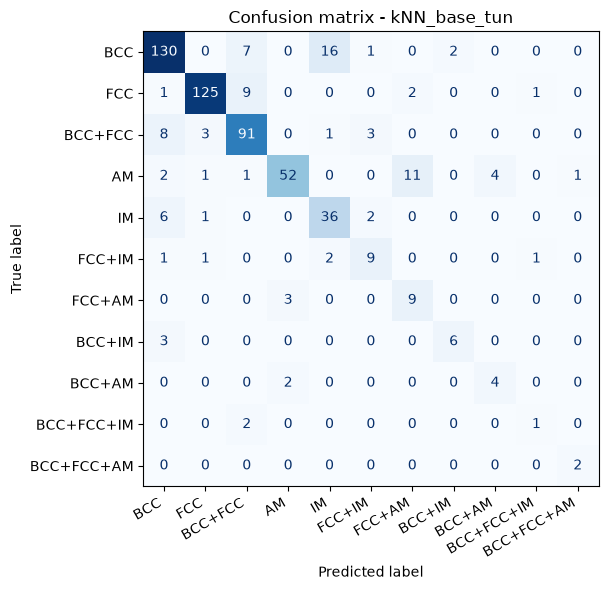

In [10]:
knn_params = {
    "clf__n_neighbors": randint(3, 16),
    "clf__weights":     ["uniform", "distance"],
    "clf__p":           [1, 2],
    "clf__metric":      ["euclidean", "manhattan", "minkowski"],
}

results = run_model(
    'kNN_base', KNeighborsClassifier(), knn_params,
    X_train, y_base_train, X_test, y_base_test, results,
)

# Multilayer Perceptron

MLP_base_def
Metrics            | Train  | Test
----------------------------------------
accuracy           | 0.8100 | 0.7922
precision_macro    | 0.6577 | 0.6715
recall_macro       | 0.6833 | 0.7132
f1_macro           | 0.6653 | 0.6717
precision_weighted | 0.8199 | 0.8071
recall_weighted    | 0.8100 | 0.7922
f1_weighted        | 0.8127 | 0.7945

              precision    recall  f1-score   support

          AM     0.9123    0.7222    0.8062        72
         BCC     0.8182    0.8077    0.8129       156
      BCC+AM     0.5000    0.3333    0.4000         6
     BCC+FCC     0.7429    0.7358    0.7393       106
  BCC+FCC+AM     0.5000    1.0000    0.6667         2
  BCC+FCC+IM     0.2000    0.3333    0.2500         3
      BCC+IM     1.0000    0.6667    0.8000         9
         FCC     0.9023    0.8696    0.8856       138
      FCC+AM     0.5500    0.9167    0.6875        12
      FCC+IM     0.6154    0.5714    0.5926        14
          IM     0.6452    0.8889    0.7477        45

 

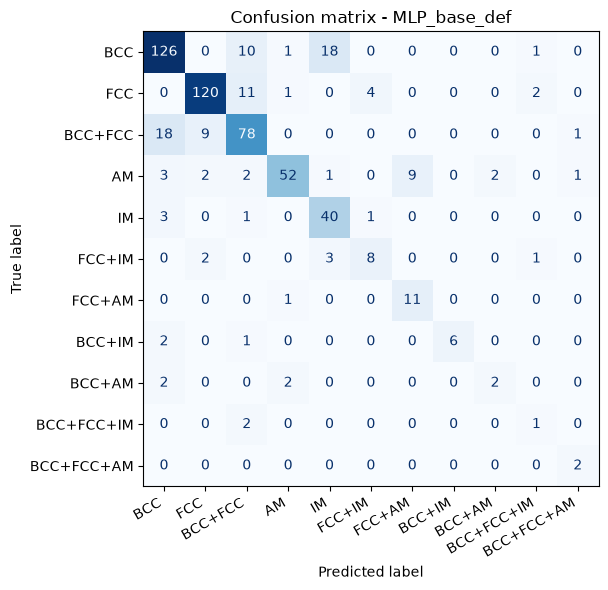

Fitting 1 folds for each of 100 candidates, totalling 100 fits

=== RandomizedSearchCV (MLP_base) ===
Best score: 0.6739
  clf__activation: tanh
  clf__alpha: 3.165039042824118e-05
  clf__batch_size: 32
  clf__hidden_layer_sizes: (64,)
  clf__learning_rate_init: 0.00268046996200036
  clf__max_iter: 500
  clf__solver: adam

MLP_base_tun
Metrics            | Train  | Test
----------------------------------------
accuracy           | 0.8340 | 0.8117
precision_macro    | 0.6959 | 0.6467
recall_macro       | 0.7670 | 0.7411
f1_macro           | 0.7156 | 0.6800
precision_weighted | 0.8569 | 0.8285
recall_weighted    | 0.8340 | 0.8117
f1_weighted        | 0.8393 | 0.8164

              precision    recall  f1-score   support

          AM     0.9138    0.7361    0.8154        72
         BCC     0.8681    0.8013    0.8333       156
      BCC+AM     0.4286    0.5000    0.4615         6
     BCC+FCC     0.8019    0.8019    0.8019       106
  BCC+FCC+AM     0.5000    1.0000    0.6667         2
 

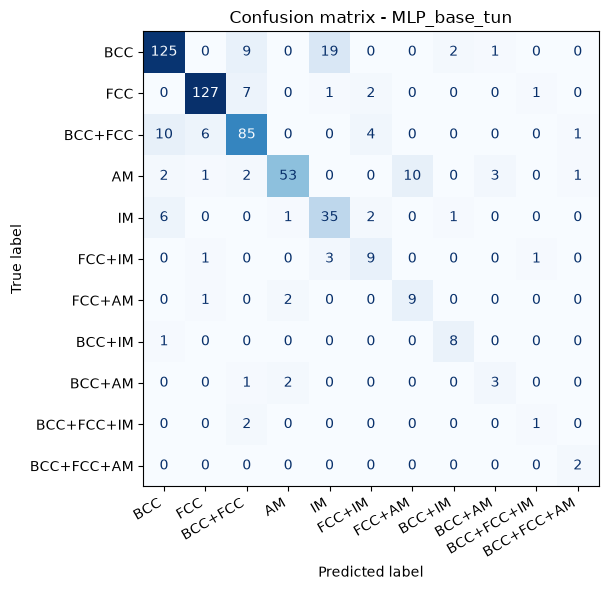

In [11]:
mlp_params = {
    "clf__hidden_layer_sizes": [(64,), (128,), (64, 32), (128, 64), (128, 64, 32)],
    "clf__activation":         ["relu", "tanh"],
    "clf__solver":             ["adam", "sgd"],
    "clf__alpha":              loguniform(1e-5, 1e-1),
    "clf__learning_rate_init": loguniform(1e-4, 1e-2),
    "clf__batch_size":         [32, 64, 128],
    "clf__max_iter":           [500],
}

results = run_model(
    "MLP_base", MLPClassifier(random_state=seed, early_stopping=True), mlp_params,
    X_train, y_base_train, X_test, y_base_test, results,
)

# Support Vector Classifier

SVC_base_def
Metrics            | Train  | Test
----------------------------------------
accuracy           | 0.7830 | 0.7780
precision_macro    | 0.5604 | 0.5758
recall_macro       | 0.5724 | 0.5604
f1_macro           | 0.5648 | 0.5638
precision_weighted | 0.7738 | 0.7704
recall_weighted    | 0.7830 | 0.7780
f1_weighted        | 0.7776 | 0.7729

              precision    recall  f1-score   support

          AM     0.8485    0.7778    0.8116        72
         BCC     0.7901    0.8205    0.8050       156
      BCC+AM     0.0000    0.0000    0.0000         6
     BCC+FCC     0.7019    0.6887    0.6952       106
  BCC+FCC+AM     0.0000    0.0000    0.0000         2
  BCC+FCC+IM     0.2000    0.3333    0.2500         3
      BCC+IM     1.0000    0.7778    0.8750         9
         FCC     0.8472    0.8841    0.8652       138
      FCC+AM     0.4167    0.4167    0.4167        12
      FCC+IM     0.8182    0.6429    0.7200        14
          IM     0.7115    0.8222    0.7629        45

 

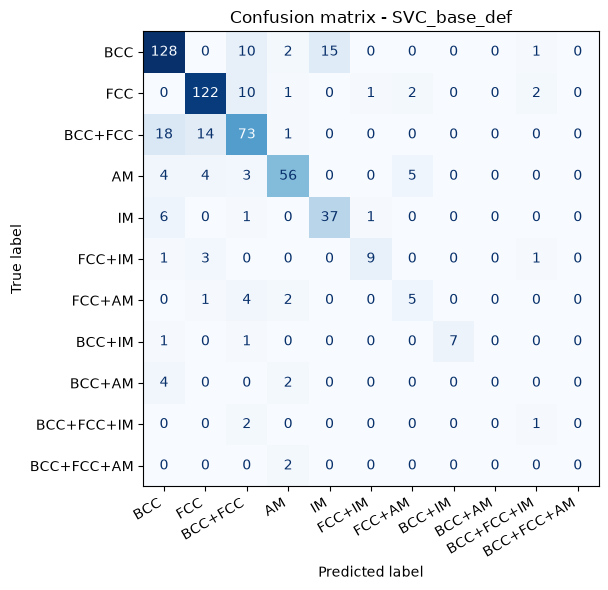

Fitting 1 folds for each of 100 candidates, totalling 100 fits

=== RandomizedSearchCV (SVC_base) ===
Best score: 0.6837
  clf__C: 4.46013243050268
  clf__coef0: 0.2504012301791798
  clf__degree: 4
  clf__gamma: 0.5198900696398738
  clf__kernel: rbf

SVC_base_tun
Metrics            | Train  | Test
----------------------------------------
accuracy           | 0.8636 | 0.8295
precision_macro    | 0.7304 | 0.6540
recall_macro       | 0.7734 | 0.6914
f1_macro           | 0.7441 | 0.6639
precision_weighted | 0.8762 | 0.8455
recall_weighted    | 0.8636 | 0.8295
f1_weighted        | 0.8669 | 0.8336

              precision    recall  f1-score   support

          AM     0.9123    0.7222    0.8062        72
         BCC     0.8684    0.8462    0.8571       156
      BCC+AM     0.3750    0.5000    0.4286         6
     BCC+FCC     0.8381    0.8302    0.8341       106
  BCC+FCC+AM     0.5000    0.5000    0.5000         2
  BCC+FCC+IM     0.3333    0.3333    0.3333         3
      BCC+IM     0.75

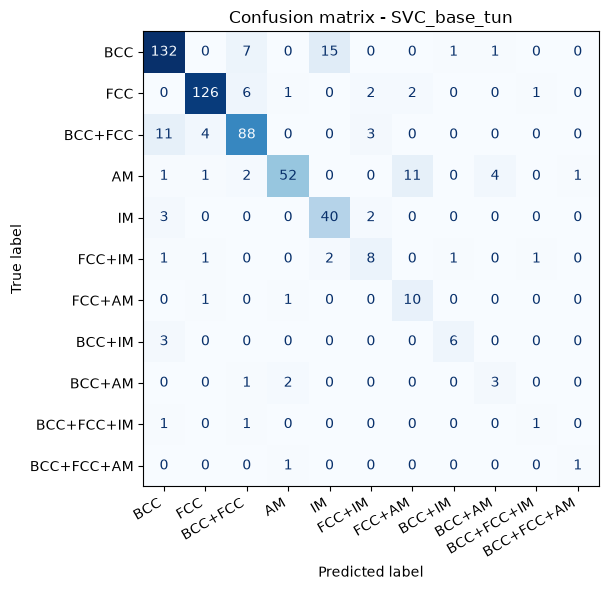

In [12]:
svc_params = {
    "clf__C":      loguniform(1e-2, 1e3),
    "clf__kernel": ["rbf", "poly", "sigmoid"],
    "clf__gamma":  loguniform(1e-4, 1e0),
    "clf__degree": randint(2, 5),
    "clf__coef0":  uniform(0, 1),
}

results = run_model(
    "SVC_base", SVC(probability=True, random_state=seed), svc_params,
    X_train, y_base_train, X_test, y_base_test, results,
)

# Random Forest

RF_base_def
Metrics            | Train  | Test
----------------------------------------
accuracy           | 0.9925 | 0.8117
precision_macro    | 0.9867 | 0.5423
recall_macro       | 0.9907 | 0.5186
f1_macro           | 0.9887 | 0.5135
precision_weighted | 0.9925 | 0.8113
recall_weighted    | 0.9925 | 0.8117
f1_weighted        | 0.9925 | 0.8088

              precision    recall  f1-score   support

          AM     0.7286    0.7083    0.7183        72
         BCC     0.8526    0.8526    0.8526       156
      BCC+AM     0.2000    0.1667    0.1818         6
     BCC+FCC     0.8919    0.9340    0.9124       106
  BCC+FCC+AM     0.0000    0.0000    0.0000         2
  BCC+FCC+IM     0.3333    0.6667    0.4444         3
      BCC+IM     0.6667    0.2222    0.3333         9
         FCC     0.9640    0.9710    0.9675       138
      FCC+AM     0.0769    0.0833    0.0800        12
      FCC+IM     0.7000    0.5000    0.5833        14
          IM     0.5510    0.6000    0.5745        45

  

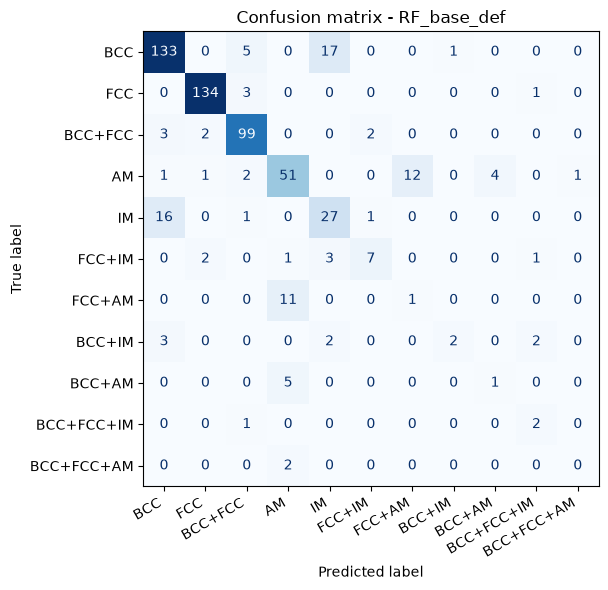

Fitting 1 folds for each of 100 candidates, totalling 100 fits

=== RandomizedSearchCV (RF_base) ===
Best score: 0.6710
  clf__bootstrap: False
  clf__class_weight: balanced
  clf__max_depth: 16
  clf__max_features: log2
  clf__min_samples_leaf: 3
  clf__min_samples_split: 18
  clf__n_estimators: 803

RF_base_tun
Metrics            | Train  | Test
----------------------------------------
accuracy           | 0.9085 | 0.8455
precision_macro    | 0.7570 | 0.6687
recall_macro       | 0.9479 | 0.8305
f1_macro           | 0.8186 | 0.7215
precision_weighted | 0.9358 | 0.8728
recall_weighted    | 0.9085 | 0.8455
f1_weighted        | 0.9139 | 0.8518

              precision    recall  f1-score   support

          AM     0.9623    0.7083    0.8160        72
         BCC     0.9137    0.8141    0.8610       156
      BCC+AM     0.5000    0.8333    0.6250         6
     BCC+FCC     0.8716    0.8962    0.8837       106
  BCC+FCC+AM     0.5000    1.0000    0.6667         2
  BCC+FCC+IM     0.4000 

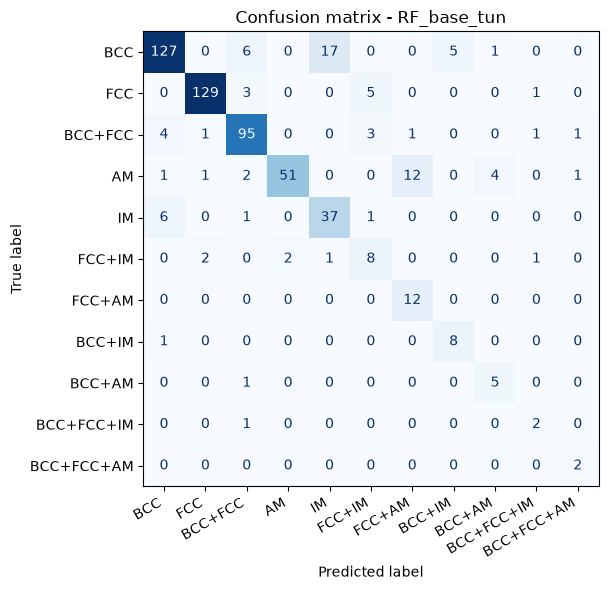

In [13]:
rf_params = {
    "clf__n_estimators":      randint(200, 1000),
    "clf__max_depth":         randint(3, 30),
    "clf__min_samples_split": randint(2, 20),
    "clf__min_samples_leaf":  randint(1, 10),
    "clf__max_features":      ["sqrt", "log2", None],
    "clf__bootstrap":         [True, False],
    "clf__class_weight":      [None, "balanced"],
}

results = run_model(
    "RF_base", RandomForestClassifier(random_state=seed, n_jobs=-1), rf_params,
    X_train, y_base_train, X_test, y_base_test, results,
)

# XGBoost

In [14]:
# Label encoded wrapper for XGBoost
class LabelEncodedXGB(BaseEstimator, ClassifierMixin):
    def __init__(self, **xgb_params):
        self.xgb_params = xgb_params

    def get_params(self, deep=True):
        return dict(self.xgb_params)

    def set_params(self, **params):
        self.xgb_params.update(params)
        return self

    def fit(self, X, y):
        self.le_ = LabelEncoder().fit(y)
        self.estimator_ = XGBClassifier(**self.xgb_params).fit(
            X, self.le_.transform(y)
        )
        self.classes_ = self.le_.classes_
        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        return self.le_.inverse_transform(
            self.estimator_.predict(X).astype(int)
        )

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)

    def decision_function(self, X):
        return self.estimator_.decision_function(X)

XGB_base_def
Metrics            | Train  | Test
----------------------------------------
accuracy           | 0.9611 | 0.8153
precision_macro    | 0.9053 | 0.5313
recall_macro       | 0.9498 | 0.5075
f1_macro           | 0.9247 | 0.5163
precision_weighted | 0.9650 | 0.8113
recall_weighted    | 0.9611 | 0.8153
f1_weighted        | 0.9620 | 0.8124

              precision    recall  f1-score   support

          AM     0.7027    0.7222    0.7123        72
         BCC     0.8693    0.8526    0.8608       156
      BCC+AM     0.0000    0.0000    0.0000         6
     BCC+FCC     0.8750    0.9245    0.8991       106
  BCC+FCC+AM     0.0000    0.0000    0.0000         2
  BCC+FCC+IM     0.3333    0.3333    0.3333         3
      BCC+IM     0.8333    0.5556    0.6667         9
         FCC     0.9635    0.9565    0.9600       138
      FCC+AM     0.0000    0.0000    0.0000        12
      FCC+IM     0.6667    0.5714    0.6154        14
          IM     0.6000    0.6667    0.6316        45

 

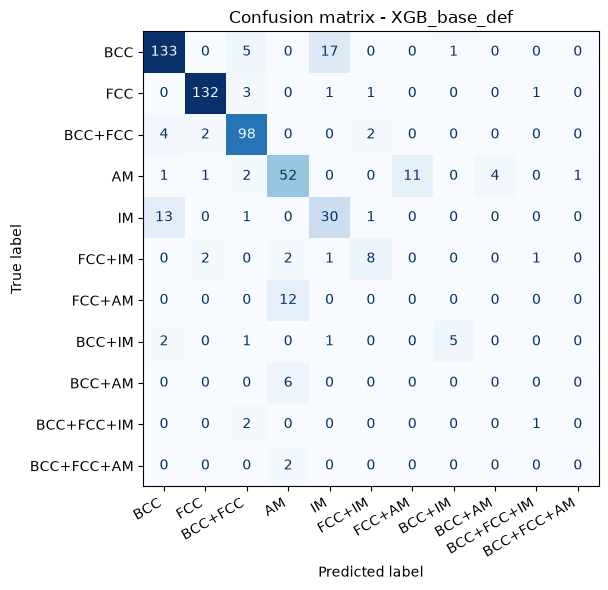

Fitting 1 folds for each of 100 candidates, totalling 100 fits

=== RandomizedSearchCV (XGB_base) ===
Best score: 0.6733
  clf__colsample_bytree: 0.685317859822822
  clf__gamma: 1.0952082130002843
  clf__learning_rate: 0.10944444888261637
  clf__max_depth: 3
  clf__min_child_weight: 9
  clf__n_estimators: 333
  clf__reg_alpha: 0.2822600936825876
  clf__reg_lambda: 0.12744547680109453
  clf__subsample: 0.7279674999966906

XGB_base_tun
Metrics            | Train  | Test
----------------------------------------
accuracy           | 0.8778 | 0.8171
precision_macro    | 0.7709 | 0.5684
recall_macro       | 0.7810 | 0.5783
f1_macro           | 0.7616 | 0.5679
precision_weighted | 0.8883 | 0.8240
recall_weighted    | 0.8778 | 0.8171
f1_weighted        | 0.8803 | 0.8177

              precision    recall  f1-score   support

          AM     0.7969    0.7083    0.7500        72
         BCC     0.8904    0.8333    0.8609       156
      BCC+AM     0.4286    0.5000    0.4615         6
     BCC+

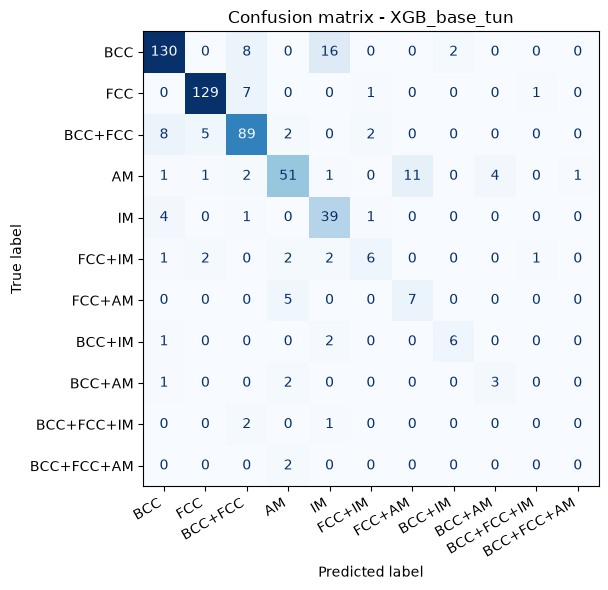

In [15]:
xgb_params = {
    "clf__n_estimators":     randint(200, 1000),
    "clf__max_depth":        randint(3, 12),
    "clf__learning_rate":    loguniform(1e-3, 3e-1),
    "clf__subsample":        uniform(0.5, 0.5),
    "clf__colsample_bytree": uniform(0.5, 0.5),
    "clf__min_child_weight": randint(1, 10),
    "clf__gamma":            loguniform(1e-3, 10),
    "clf__reg_alpha":        loguniform(1e-3, 10),
    "clf__reg_lambda":       loguniform(1e-3, 10),
}

results = run_model(
    "XGB_base", LabelEncodedXGB(random_state=seed, tree_method="hist", eval_metric="logloss"), xgb_params,
    X_train, y_base_train, X_test, y_base_test, results,
)

# Summary

In [16]:
summary = summarize_models(results)
display(summary.round(4))

,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
Model,,,,,,,
kNN_base_def,0.8366,0.6872,0.7157,0.6869,0.8542,0.8366,0.8418
kNN_base_tun,0.8259,0.6789,0.7436,0.7005,0.8423,0.8259,0.8305
MLP_base_def,0.7922,0.6715,0.7132,0.6717,0.8071,0.7922,0.7945
MLP_base_tun,0.8117,0.6467,0.7411,0.6800,0.8285,0.8117,0.8164
SVC_base_def,0.7780,0.5758,0.5604,0.5638,0.7704,0.7780,0.7729
SVC_base_tun,0.8295,0.6540,0.6914,0.6639,0.8455,0.8295,0.8336
RF_base_def,0.8117,0.5423,0.5186,0.5135,0.8113,0.8117,0.8088
RF_base_tun,0.8455,0.6687,0.8305,0.7215,0.8728,0.8455,0.8518
XGB_base_def,0.8153,0.5313,0.5075,0.5163,0.8113,0.8153,0.8124


In [17]:
def results_to_csv(results, phase_combs, path="results.csv"):
    rows = []
    for r in results:
        row = {"name": r["name"]}

        # metrics (train + test)
        for split in ("train", "test"):
            for metric, value in r[split].items():
                row[f"{split}_{metric}"] = value

        # confusion matrix, one column per (true, pred) cell
        cm = r["cm"]
        for i, true_label in enumerate(phase_combs):
            for j, pred_label in enumerate(phase_combs):
                row[f"cm_true={true_label}|pred={pred_label}"] = cm[i, j]

        rows.append(row)

    return pd.DataFrame(rows)

df = results_to_csv(results, phase_combs)
df.to_csv("data/baseline_results.csv", index=False)